# Gratuity Valuation Project: Stage 1 

**Purpose:** load and check the synthetic employee census that the later valuation stages will use.

**Important:** all data here are synthetic (randomly generated for learning). Nothing describes a real organisation or person.

**Valuation date:** 31 March 2026

##  Cell 1: Settings and importing the libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

VALUATION_DATE = pd.Timestamp("2026-03-31")
RETIREMENT_AGE = 60

##  Cell 2: Load the CSV



In [2]:
df = pd.read_csv(
    "synthetic_employee_data.csv",
    parse_dates=["date_of_birth", "date_of_joining"],
)
df.shape

C:\Users\Paras Gulati\AppData\Local\Temp\ipykernel_200\1143772448.py:1: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df = pd.read_csv(
C:\Users\Paras Gulati\AppData\Local\Temp\ipykernel_200\1143772448.py:1: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df = pd.read_csv(


(150, 4)

## Cell 3: First look at the data

In [3]:
display(df.head())
df.info()

,emp_id,date_of_birth,date_of_joining,monthly_wages_rs
0,E001,1996-03-22,2022-12-19,23700
1,E002,1992-10-26,2023-08-09,33500
2,E003,1986-04-11,2012-05-06,99400
3,E004,1986-09-16,2020-07-03,44200
4,E005,1990-12-20,2016-10-14,49000


<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 4 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   emp_id            150 non-null    str           
 1   date_of_birth     150 non-null    datetime64[us]
 2   date_of_joining   150 non-null    datetime64[us]
 3   monthly_wages_rs  150 non-null    int64         
dtypes: datetime64[us](2), int64(1), str(1)
memory usage: 4.8 KB


##  Cell 4: Derive age and service at the valuation date

Age and service are measured in years, using 365.25 days per year.

In [4]:
df["age"] = (VALUATION_DATE - df["date_of_birth"]).dt.days / 365.25
df["service_years"] = (VALUATION_DATE - df["date_of_joining"]).dt.days / 365.25
df["age_at_joining"] = df["age"] - df["service_years"]
df[["emp_id", "age", "service_years", "age_at_joining", "monthly_wages_rs"]].head()

,emp_id,age,service_years,age_at_joining,monthly_wages_rs
0,E001,30.023272,3.279945,26.743326,23700
1,E002,33.426420,2.642026,30.784394,33500
2,E003,39.969884,13.900068,26.069815,99400
3,E004,39.537303,5.741273,33.796030,44200
4,E005,35.277207,9.459274,25.817933,49000


##  Cell 5: Data quality checks


In [5]:
assert df["emp_id"].is_unique, "Duplicate employee IDs"
assert df.notna().all().all(), "Missing values found"
assert (df["date_of_joining"] <= VALUATION_DATE).all(), "Joined after valuation date"
assert (df["age_at_joining"] >= 21 - 0.01).all(), "Joined before age 21"
assert (df["age"] < RETIREMENT_AGE).all(), "Employee at or past retirement age"
assert (df["monthly_wages_rs"] > 0).all(), "Non-positive wages"
print("All data quality checks passed")

All data quality checks passed


##  Cell 6: The part-year rule

Under the Code on Social Security, a part-year of more than six months counts as a full year. We write it as a function and test it, because every benefit calculation in later stages depends on it.

In [6]:
def completed_years_rounded(service_years):
    """Whole years of service, counting a part-year over six months as a full year."""
    whole = np.floor(service_years)
    part = service_years - whole
    return np.where(part > 0.5, whole + 1, whole)

# Test cases (5 years 5 months, 5 years 7 months, exactly 5 years)
print(completed_years_rounded(np.array([5 + 5/12, 5 + 7/12, 5.0])))   # expect [5. 6. 5.]

df["service_for_formula"] = completed_years_rounded(df["service_years"])

[5. 6. 5.]


## Cell 7: Statutory benefit if every employee left today

Formula: (15 / 26) x monthly wages x years. This is **not** the DBO. It ignores discounting, future wage growth, exit probabilities and the eligibility rule. We calculate it only to compare with the DBO in later stages. The ceiling is applied.

In [7]:
CEILING = 2_000_000   # Rs 20 lakh; verify against the current notification

df["benefit_if_exit_today"] = np.minimum(
    15 / 26 * df["monthly_wages_rs"] * df["service_for_formula"], CEILING
)
df["eligible_today"] = df["service_years"] >= 5   # simplified five-year test

print("Employees:", len(df))
print("Eligible today (>= 5 years):", int(df["eligible_today"].sum()))
print("Total benefit if all eligible employees left today (Rs):",
      int(df.loc[df["eligible_today"], "benefit_if_exit_today"].sum()))

Employees: 150
Eligible today (>= 5 years): 100
Total benefit if all eligible employees left today (Rs): 78425826


## Cell 8: Summary statistics

In [8]:
df[["age", "service_years", "monthly_wages_rs"]].describe().round(1)

,age,service_years,monthly_wages_rs
count,150.0,150.0,150.0
mean,38.0,10.4,75774.7
std,8.0,7.7,59661.3
min,22.8,0.2,18500.0
25%,32.1,4.0,39275.0
50%,37.0,8.8,55000.0
75%,43.2,15.0,84050.0
max,55.6,31.5,300000.0


## Cell 9: Charts

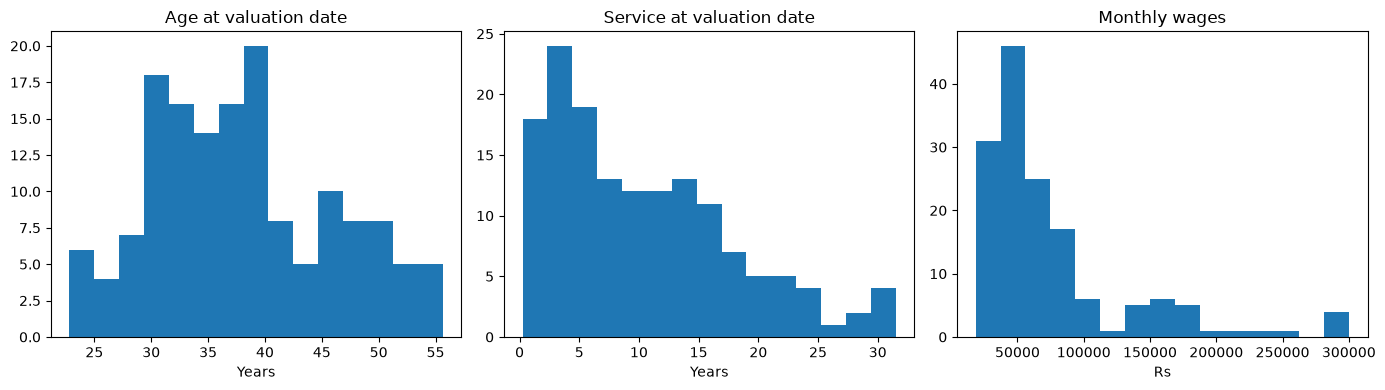

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].hist(df["age"], bins=15)
axes[0].set_title("Age at valuation date")
axes[0].set_xlabel("Years")

axes[1].hist(df["service_years"], bins=15)
axes[1].set_title("Service at valuation date")
axes[1].set_xlabel("Years")

axes[2].hist(df["monthly_wages_rs"], bins=15)
axes[2].set_title("Monthly wages")
axes[2].set_xlabel("Rs")

plt.tight_layout()
plt.show()

##  Cell 10: Observations (Until now)

The employee group is young, with a mean age of 38 and 98 of 150 employees under 40, so most gratuity payments fall many years ahead. One-third of employees (50) have under 5 years of service and are not yet eligible, which makes the withdrawal assumption important. Wages are right-skewed (mean ₹75,775 against median ₹55,000), and the top 10 eligible employees account for about a quarter of the reference benefit of ₹7.84 crore. The ₹20 lakh ceiling already binds for 15 employees.

---
# Stage 2: Assumptions and Decrements

**Purpose:** set the valuation assumptions and build the probabilities that an employee leaves service in each future year.

**Important:** these assumptions are **illustrative**. The mortality curve and withdrawal rates are placeholders for learning, not published or company-specific figures. 



## Cell 11: Settings and assumptions


In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ASSUMPTIONS = {
    "valuation_date": pd.Timestamp("2026-03-31"),
    "retirement_age": 60,
    "discount_rate": 0.07,          # ~10-year G-sec yield around the valuation date (check and cite your source)
    "salary_escalation": 0.08,      # illustrative; document the reasoning in your report
    "ceiling": 2_000_000,           # Rs 20 lakh; verify against the current notification
    # Illustrative Gompertz-Makeham mortality: force of mortality = A + B * c**x
    "mort_A": 0.0004,
    "mort_B": 0.00002,
    "mort_c": 1.10,
}

# Illustrative annual withdrawal rates (resignation/termination) by age band: (from_age, to_age_exclusive, rate)
WITHDRAWAL_BANDS = [
    (18, 25, 0.20),
    (25, 30, 0.15),
    (30, 35, 0.11),
    (35, 40, 0.08),
    (40, 45, 0.05),
    (45, 50, 0.03),
    (50, 55, 0.02),
    (55, 60, 0.01),
]

## Cell 12: Mortality

Under a Gompertz-Makeham law the force of mortality is A + B c^x. The probability of dying within one year starting at exact age x is 1 - exp(-integral of the force over that year).

In [11]:
def mortality_q(x, a=ASSUMPTIONS):
    """One-year probability of death at age x (illustrative Gompertz-Makeham)."""
    A, B, c = a["mort_A"], a["mort_B"], a["mort_c"]
    integral = A + B * c**x * (c - 1) / np.log(c)
    return 1 - np.exp(-integral)

for age in [25, 30, 40, 50, 59]:
    print(f"q at age {age}: {mortality_q(age):.5f}")

q at age 25: 0.00063
q at age 30: 0.00077
q at age 40: 0.00135
q at age 50: 0.00286
q at age 59: 0.00619


## Cell 13: Withdrawal (resignation or termination)

In [12]:
def withdrawal_w(x, bands=WITHDRAWAL_BANDS):
    """Annual probability of withdrawal at age x, from the age-band table."""
    for lo, hi, rate in bands:
        if lo <= x < hi:
            return rate
    return 0.0

for age in [22, 28, 33, 38, 43, 48, 53, 58]:
    print(f"w at age {age}: {withdrawal_w(age):.2f}")

w at age 22: 0.20
w at age 28: 0.15
w at age 33: 0.11
w at age 38: 0.08
w at age 43: 0.05
w at age 48: 0.03
w at age 53: 0.02
w at age 58: 0.01


## Cell 14: Decrement table for one employee

Each year an in-service employee can die, withdraw or stay. We combine the two rates so they do not double count: the death probability is q x (1 - w/2) and the withdrawal probability is w x (1 - q/2). Survivors who reach the retirement age retire at the end of the last year.

Simplification: age is rounded down to whole years and all exits are treated as happening at the end of the year.

In [13]:
def exit_table(age_now, a=ASSUMPTIONS):
    """Probability of each type of exit in each future year for an employee aged age_now."""
    ret = a["retirement_age"]
    start_age = int(np.floor(age_now))
    rows = []
    in_service = 1.0                       # probability still in service at the start of the year
    for t in range(1, ret - start_age + 1):
        x = start_age + t - 1              # age at the start of year t
        q = mortality_q(x)
        w = withdrawal_w(x)
        p_death = in_service * q * (1 - w / 2)
        p_withdraw = in_service * w * (1 - q / 2)
        p_stay = in_service - p_death - p_withdraw
        p_retire = p_stay if t == ret - start_age else 0.0
        rows.append({
            "t": t,
            "age_at_start": x,
            "in_service_start": in_service,
            "p_death": p_death,
            "p_withdraw": p_withdraw,
            "p_retire": p_retire,
        })
        in_service = p_stay
    return pd.DataFrame(rows)

tbl = exit_table(35)
tbl.round(4).head(10)

,t,age_at_start,in_service_start,p_death,p_withdraw,p_retire
0,1,35,1.0000,0.0009,0.0800,0.0
1,2,36,0.9191,0.0009,0.0735,0.0
2,3,37,0.8447,0.0009,0.0675,0.0
3,4,38,0.7762,0.0009,0.0621,0.0
4,5,39,0.7133,0.0009,0.0570,0.0
5,6,40,0.6554,0.0009,0.0327,0.0
6,7,41,0.6218,0.0009,0.0311,0.0
7,8,42,0.5898,0.0009,0.0295,0.0
8,9,43,0.5595,0.0009,0.0280,0.0
9,10,44,0.5306,0.0009,0.0265,0.0


## Cell 15: Check that probabilities add up to 1

If the total of all exit probabilities is not exactly 1, the table is wrong and every later number will be wrong too.

In [14]:
total = tbl[["p_death", "p_withdraw", "p_retire"]].sum().sum()
print("Sum of all exit probabilities:", round(total, 10))
assert abs(total - 1) < 1e-9
print("Check passed")

print("Probability of ending service by death     :", round(tbl.p_death.sum(), 4))
print("Probability of ending service by withdrawal:", round(tbl.p_withdraw.sum(), 4))
print("Probability of reaching retirement          :", round(tbl.p_retire.sum(), 4))

Sum of all exit probabilities: 1.0
Check passed
Probability of ending service by death     : 0.0306
Probability of ending service by withdrawal: 0.6177
Probability of reaching retirement          : 0.3517


## Cell 16: Chart of exits by year for an employee aged 35

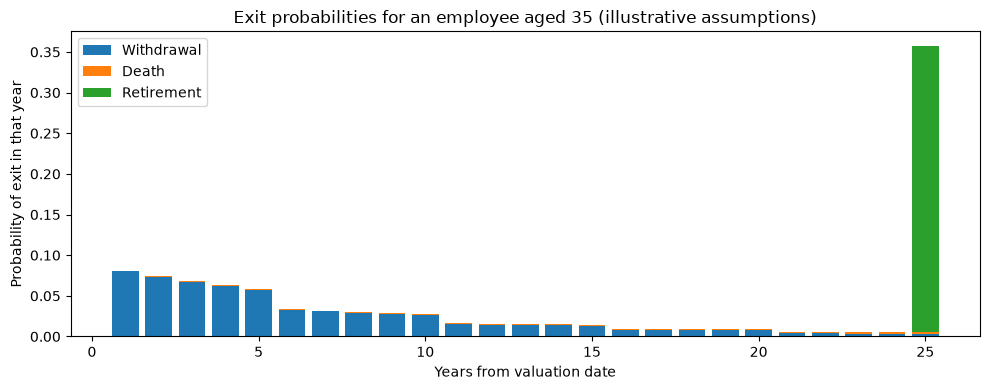

In [15]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(tbl["t"], tbl["p_withdraw"], label="Withdrawal")
ax.bar(tbl["t"], tbl["p_death"], bottom=tbl["p_withdraw"], label="Death")
ax.bar(tbl["t"], tbl["p_retire"], bottom=tbl["p_withdraw"] + tbl["p_death"], label="Retirement")
ax.set_xlabel("Years from valuation date")
ax.set_ylabel("Probability of exit in that year")
ax.set_title("Exit probabilities for an employee aged 35 (illustrative assumptions)")
ax.legend()
plt.tight_layout()
plt.show()

## Cell 17: Compare ages

Run the table for three different ages and compare. This shows why the withdrawal assumption matters more for young employees.

In [16]:
rows = []
for age in [25, 35, 45, 55]:
    t = exit_table(age)
    rows.append({
        "age": age,
        "years_to_retirement": ASSUMPTIONS["retirement_age"] - age,
        "P(withdraw)": round(t.p_withdraw.sum(), 3),
        "P(death)": round(t.p_death.sum(), 4),
        "P(reach retirement)": round(t.p_retire.sum(), 3),
    })
pd.DataFrame(rows)

,age,years_to_retirement,P(withdraw),P(death),P(reach retirement)
0,25,35,0.902,0.0112,0.086
1,35,25,0.618,0.0306,0.352
2,45,15,0.258,0.0430,0.699
3,55,5,0.048,0.0252,0.926


## Cell 18:Observations

**Withdrawal dominates exits**:An employee aged 35 has a 61.8% chance of leaving by withdrawal and 35.2% of reaching retirement. Death is only 3.1%.
**Exit risk is highest early and falls with time**: The chart shows 8.0% in year 1, then smaller bars, because the in-service group shrinks and **withdrawal rates step down with age**. The tall bar in the last year is retirement, which is all remaining survivors leaving at once.
**Reaching retirement becomes likelier with age**: It is 8.6% at 25, 35.2% at 35, 69.9% at 45 and 92.6% at 55.
**The death probability is not monotonic by age:** 3.1% at 35, 4.3% at 45 and 2.5% at 55. Mortality per year rises with age, but a 55-year-old has only 5 years of exposure. The pattern combines yearly risk and years remaining.
**Link to the liability:** most leavers go early with short service, so many are either ineligible (under 5 years) or receive small benefits. The liability is driven by the minority who stay long.

# Stage 3: The Valuation Engine (Projected Unit Credit)

 It uses `df`, `ASSUMPTIONS`, `exit_table()` and `completed_years_rounded()` from the earlier stages.

**What it calculates for each employee:** the expected gratuity payable in each future year, the share of it earned so far (attributed by service), and the present value of that share. The sum across employees is the DBO.

**Simplifications :**
- Ages are rounded down to whole years and all exits occur at the end of a year.
- The ceiling is applied to the projected benefit, then the benefit is attributed in proportion to service.
- Death is paid regardless of service length. Withdrawal is paid only if service at exit is 5 years or more. Retirement is paid if service is 5 years or more (always true for the cases here).
- Interest cost is approximated as discount rate x opening DBO.

## Cell 19: The valuation function for one employee

In [24]:
def value_employee(age_now, service_now, wage, a=ASSUMPTIONS, table=None):
    """Projected Unit Credit valuation of gratuity for one employee.
    Returns DBO, current service cost and the expected payment by future year."""
    if table is None:
        table = exit_table(age_now, a)

    t = table["t"].to_numpy()
    v = 1 / (1 + a["discount_rate"])

    service_t = service_now + t                                   # service at exit
    wage_t = wage * (1 + a["salary_escalation"]) ** t             # projected monthly wages at exit
    years_t = completed_years_rounded(service_t)                  # part-year rule
    benefit_t = np.minimum(15 / 26 * wage_t * years_t, a["ceiling"])

    withdrawal_paid = (service_t >= 5).astype(float)              # five-year rule for withdrawals
    prob_paid = table["p_death"].to_numpy() + table["p_retire"].to_numpy() \
                + table["p_withdraw"].to_numpy() * withdrawal_paid

    expected_benefit = prob_paid * benefit_t                      # expected payment at the end of year t
    attributed = expected_benefit * service_now / service_t       # share earned to date (PUC)
    disc = v ** t

    return {
        "dbo": float((attributed * disc).sum()),
        "service_cost": float((expected_benefit / service_t * disc).sum()),
        "attributed_by_year": attributed,
        "detail": pd.DataFrame({
            "t": t, "service_at_exit": service_t.round(2), "wage_at_exit": wage_t.round(0),
            "years_for_formula": years_t, "benefit_if_paid": benefit_t.round(0),
            "prob_paid": prob_paid.round(4), "expected_benefit": expected_benefit.round(0),
            "share_earned": (service_now / service_t).round(3), "discount_factor": disc.round(4),
            "pv_attributed": (attributed * disc).round(0),
        }),
    }

## Cell 20: Validate against the hand example

Before trusting the function on 150 employees, testing it on a case we can calculate by hand: age 40, 10 years of service, wages Rs 60,000, retires at 60 with certainty, wage growth 6%, discount rate 7%. By hand: DBO = Rs 1,72,279 and service cost = Rs 17,228.

In [18]:
a_test = {**ASSUMPTIONS, "discount_rate": 0.07, "salary_escalation": 0.06}

# A table where the employee retires with certainty at t = 20 and nothing else happens
test_table = pd.DataFrame({"t": range(1, 21)})
test_table["p_death"] = 0.0
test_table["p_withdraw"] = 0.0
test_table["p_retire"] = 0.0
test_table.loc[test_table["t"] == 20, "p_retire"] = 1.0

res = value_employee(age_now=40, service_now=10, wage=60000, a=a_test, table=test_table)
print("DBO         :", round(res["dbo"]))
print("Service cost:", round(res["service_cost"]))

assert abs(res["dbo"] - 172279) < 5, "DBO does not match the hand calculation"
assert abs(res["service_cost"] - 17228) < 2, "Service cost does not match the hand calculation"
print("Validation passed: the function reproduces the hand calculation")

DBO         : 172279
Service cost: 17228
Validation passed: the function reproduces the hand calculation


## Cell 21: Follow one employee's calculation line by line

Pick any employee and read the working. 

In [19]:
emp = df[df["emp_id"] == "E003"].iloc[0]
r = value_employee(emp["age"], emp["service_years"], emp["monthly_wages_rs"])
print(f"E003: age {emp['age']:.1f}, service {emp['service_years']:.1f} years, wages Rs {emp['monthly_wages_rs']:,}")
print(f"DBO: Rs {r['dbo']:,.0f}   Service cost: Rs {r['service_cost']:,.0f}")
r["detail"].head(8)

E003: age 40.0, service 13.9 years, wages Rs 99,400
DBO: Rs 445,115   Service cost: Rs 32,023


,t,service_at_exit,wage_at_exit,years_for_formula,benefit_if_paid,prob_paid,expected_benefit,share_earned,discount_factor,pv_attributed
0,1,14.9,107352.0,15.0,929008.0,0.0812,75400.0,0.933,0.9346,65738.0
1,2,15.9,115940.0,16.0,1070217.0,0.0471,50428.0,0.874,0.8734,38505.0
2,3,16.9,125215.0,17.0,1228074.0,0.0448,54995.0,0.822,0.8163,36923.0
3,4,17.9,135233.0,18.0,1404339.0,0.0426,59773.0,0.777,0.7629,35410.0
4,5,18.9,146051.0,19.0,1600946.0,0.0405,64771.0,0.735,0.7130,33964.0
5,6,19.9,157735.0,20.0,1820023.0,0.0385,69998.0,0.698,0.6663,32580.0
6,7,20.9,170354.0,21.0,2000000.0,0.0225,44966.0,0.665,0.6227,18624.0
7,8,21.9,183982.0,22.0,2000000.0,0.0219,43735.0,0.635,0.5820,16156.0


## Cell 22: Value all employees

In [20]:
max_t = ASSUMPTIONS["retirement_age"] - int(np.floor(df["age"].min()))
cash_by_year = np.zeros(max_t)          # expected payments for past service, by year, summed over employees

rows = []
for _, e in df.iterrows():
    r = value_employee(e["age"], e["service_years"], e["monthly_wages_rs"])
    cash_by_year[: len(r["attributed_by_year"])] += r["attributed_by_year"]
    rows.append({"emp_id": e["emp_id"], "age": e["age"], "service_years": e["service_years"],
                 "monthly_wages_rs": e["monthly_wages_rs"], "dbo": r["dbo"], "service_cost": r["service_cost"]})

results = pd.DataFrame(rows)

total_dbo = results["dbo"].sum()
total_sc = results["service_cost"].sum()
interest_cost = ASSUMPTIONS["discount_rate"] * total_dbo

print(f"Total DBO at valuation date    : Rs {total_dbo:,.0f}  (Rs {total_dbo/1e7:.2f} crore)")
print(f"Current service cost (next yr) : Rs {total_sc:,.0f}")
print(f"Interest cost (approx.)        : Rs {interest_cost:,.0f}")
print(f"Expected benefit payments, year 1 (past service): Rs {cash_by_year[0]:,.0f}")

Total DBO at valuation date    : Rs 46,785,528  (Rs 4.68 crore)
Current service cost (next yr) : Rs 3,723,248
Interest cost (approx.)        : Rs 3,274,987
Expected benefit payments, year 1 (past service): Rs 3,990,406


## Cell 23: Checks

Two independent checks that the numbers hang together.

In [21]:
# Check 1: discounting the cash-flow projection must give back the DBO
v = 1 / (1 + ASSUMPTIONS["discount_rate"])
pv_from_cash = (cash_by_year * v ** np.arange(1, max_t + 1)).sum()
print("DBO from employee table :", round(total_dbo))
print("DBO from cash-flow table:", round(pv_from_cash))
assert abs(total_dbo - pv_from_cash) < 1, "Cash-flow projection does not reconcile to the DBO"

# Check 2: no negative values, and every employee has a positive DBO
assert (results["dbo"] >= 0).all()
print("All checks passed")

# Weighted average time to payment (duration) of the liability
years = np.arange(1, max_t + 1)
pv_by_year = cash_by_year * v ** years
duration = (years * pv_by_year).sum() / pv_by_year.sum()
print(f"Weighted average term of the liability: {duration:.1f} years")

DBO from employee table : 46785528
DBO from cash-flow table: 46785528
All checks passed
Weighted average term of the liability: 8.7 years


## Cell 24: Compare with the Stage 1 reference figure

In [22]:
reference = df.loc[df["eligible_today"], "benefit_if_exit_today"].sum()
print(f"Benefit if all eligible employees left today (Stage 1): Rs {reference:,.0f}")
print(f"DBO from the valuation                               : Rs {total_dbo:,.0f}")
print(f"DBO as a share of the Stage 1 reference figure       : {total_dbo / reference:.1%}")

Benefit if all eligible employees left today (Stage 1): Rs 78,425,827
DBO from the valuation                               : Rs 46,785,528
DBO as a share of the Stage 1 reference figure       : 59.7%


## Cell 25: Where the liability sits

Top 10 employees hold 22.8% of the DBO


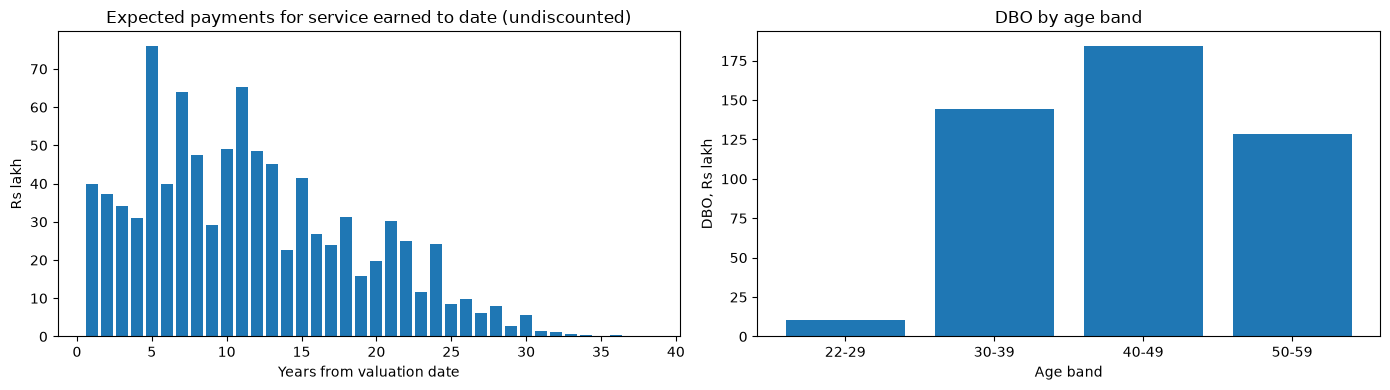

In [23]:
top10 = results.sort_values("dbo", ascending=False).head(10)
print(f"Top 10 employees hold {top10['dbo'].sum() / total_dbo:.1%} of the DBO")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].bar(range(1, max_t + 1), cash_by_year / 1e5)
axes[0].set_xlabel("Years from valuation date")
axes[0].set_ylabel("Rs lakh")
axes[0].set_title("Expected payments for service earned to date (undiscounted)")

bands = pd.cut(results["age"], bins=[20, 30, 40, 50, 60], right=False,
               labels=["22-29", "30-39", "40-49", "50-59"])
axes[1].bar(results.groupby(bands, observed=True)["dbo"].sum().index.astype(str),
            results.groupby(bands, observed=True)["dbo"].sum() / 1e5)
axes[1].set_xlabel("Age band")
axes[1].set_ylabel("DBO, Rs lakh")
axes[1].set_title("DBO by age band")

plt.tight_layout()
plt.show()

## Cell 26: Observations 

**The DBO is ₹4.68 crore, or 59.7% of the Stage 1 reference figure of ₹7.84 crore**: The reference assumes everyone eligible leaves today. The DBO discounts payments that average about 8.7 years away, weights them by exit probabilities, and counts only the share of each benefit earned so far. Wage growth of 8% a year and the 50 employees not yet eligible pull the other way, but discounting and attribution outweigh them.

**The liability grows by service cost plus interest, and shrinks by payments**: Next year’s service cost is ₹37.2 lakh (8.0% of the DBO) and interest cost is about ₹32.7 lakh. Together they add roughly ₹70 lakh. Expected payments for past service in year 1 are ₹39.9 lakh, which take roughly ₹40 lakh out.

**The weighted average term is 8.7 years, against about 22 years to retirement for the average employee**: Most expected payments come from early exits, and discounting gives near-term payments more weight.

**The liability is concentrated**: The top 10 employees hold 22.8% of the DBO while being 6.7% of headcount, about 3.4 times their share.